In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ==========================================================
# Machine Learning Pipeline
# ==========================================================

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Utilities
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.preprocessing import StandardScaler

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve
)

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Figure Style
plt.style.use("default")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# ==========================================================
# Create Output Directories
# ==========================================================

import os
FIGURE_DIR = "/content/drive/MyDrive/CKD Research Project/Figures"
RESULT_DIR = "/content/drive/MyDrive/CKD Research Project/Results"
MODEL_DIR = "/content/drive/MyDrive/CKD Research Project/Saved_Models"

os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

In [5]:
# ==========================================================
# Load Processed Dataset
# ==========================================================

DATA_PATH = "./drive/MyDrive/CKD Research Project/Dataset/clean_ckd.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.\n")
print(f"Dataset Shape: {df.shape}")

display(df.head())

Dataset loaded successfully.

Dataset Shape: (399, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0


In [6]:
# ==========================================================
# Dataset Verification
# ==========================================================

print("=" * 60)
print("Dataset Information")
print("=" * 60)

display(df.info())

print("\nMissing Values")
display(df.isnull().sum())

print("\nDuplicate Records :", df.duplicated().sum())

print("\nTarget Distribution")
display(df["class"].value_counts())

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     399 non-null    float64
 1   bp      399 non-null    float64
 2   sg      399 non-null    float64
 3   al      399 non-null    float64
 4   su      399 non-null    float64
 5   rbc     399 non-null    int64  
 6   pc      399 non-null    int64  
 7   pcc     399 non-null    int64  
 8   ba      399 non-null    int64  
 9   bgr     399 non-null    float64
 10  bu      399 non-null    float64
 11  sc      399 non-null    float64
 12  sod     399 non-null    float64
 13  pot     399 non-null    float64
 14  hemo    399 non-null    float64
 15  pcv     399 non-null    float64
 16  wbcc    399 non-null    float64
 17  rbcc    399 non-null    float64
 18  htn     399 non-null    int64  
 19  dm      399 non-null    int64  
 20  cad     399 non-null    int64  
 21  appet   399 non-nul

None


Missing Values


,0
age,0
bp,0
sg,0
al,0
su,0
rbc,0
pc,0
pcc,0
ba,0
bgr,0



Duplicate Records : 0

Target Distribution


,count
class,
0,250
1,149


In [7]:
# ==========================================================
# Section 5: Feature and Target Selection
# ==========================================================

TARGET = "class"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f"Feature Matrix Shape : {X.shape}")
print(f"Target Vector Shape  : {y.shape}")

Feature Matrix Shape : (399, 24)
Target Vector Shape  : (399,)


In [8]:
# ==========================================================
# Section 6: Train-Test Split
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training Set")
print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}")

print("\nTesting Set")
print(f"X_test  : {X_test.shape}")
print(f"y_test  : {y_test.shape}")

Training Set
X_train : (319, 24)
y_train : (319,)

Testing Set
X_test  : (80, 24)
y_test  : (80,)


In [9]:
# ==========================================================
# Section 7: Class Distribution
# ==========================================================

print("Training Set Class Distribution")
display(y_train.value_counts())

print("\nTesting Set Class Distribution")
display(y_test.value_counts())

Training Set Class Distribution


,count
class,
0,200
1,119



Testing Set Class Distribution


,count
class,
0,50
1,30


In [10]:
# ==========================================================
# Section 8: Feature Scaling
# ==========================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

print(f"Scaled Training Shape : {X_train_scaled.shape}")
print(f"Scaled Testing Shape  : {X_test_scaled.shape}")

Feature scaling completed successfully.
Scaled Training Shape : (319, 24)
Scaled Testing Shape  : (80, 24)


In [11]:
# ==========================================================
# Section 9: Model Evaluation Function
# ==========================================================

def evaluate_model(model, X_test, y_test):

    # Prediction
    y_pred = model.predict(X_test)

    # Probability (for ROC-AUC)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    # Performance Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print("=" * 60)
    print(type(model).__name__)
    print("=" * 60)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    if y_prob is not None:
        roc_auc = roc_auc_score(y_test, y_prob)
        print(f"ROC-AUC  : {roc_auc:.4f}")

    print("\nClassification Report")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {type(model).__name__}")
    plt.show()

    return {
        "Model": type(model).__name__,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": roc_auc if y_prob is not None else None
    }

LogisticRegression
Accuracy : 0.9875
Precision: 0.9677
Recall   : 1.0000
F1-Score : 0.9836
ROC-AUC  : 0.9993

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.97      1.00      0.98        30

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



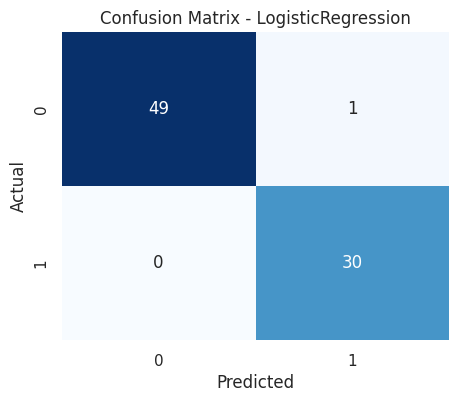

In [12]:
# ==========================================================
# Section 10: Logistic Regression
# ==========================================================

from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    random_state=RANDOM_STATE
)

log_reg.fit(X_train_scaled, y_train)

lr_results = evaluate_model(
    log_reg,
    X_test_scaled,
    y_test
)

In [13]:
# ==========================================================
# Section 11: Results Container
# ==========================================================

results = []

# Add Logistic Regression Result
results.append(lr_results)

KNeighborsClassifier
Accuracy : 0.9875
Precision: 0.9677
Recall   : 1.0000
F1-Score : 0.9836
ROC-AUC  : 0.9890

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.97      1.00      0.98        30

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



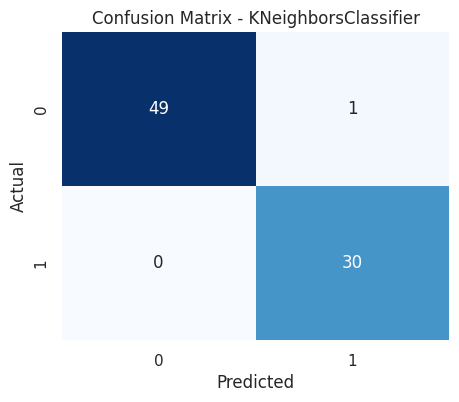

In [14]:
# ==========================================================
# Section 12: K-Nearest Neighbors
# ==========================================================

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

knn_results = evaluate_model(
    knn,
    X_test_scaled,
    y_test
)

results.append(knn_results)

DecisionTreeClassifier
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9667

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



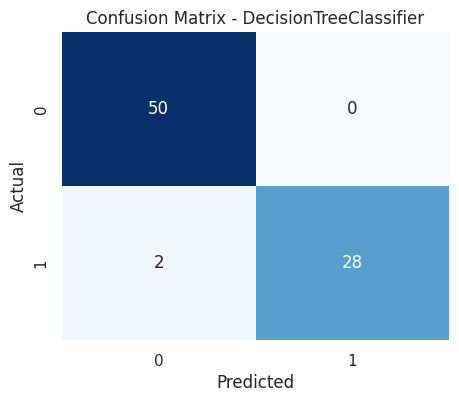

In [15]:
# ==========================================================
# Section 13: Decision Tree
# ==========================================================

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

dt.fit(X_train, y_train)

dt_results = evaluate_model(
    dt,
    X_test,
    y_test
)

results.append(dt_results)

RandomForestClassifier
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9993

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



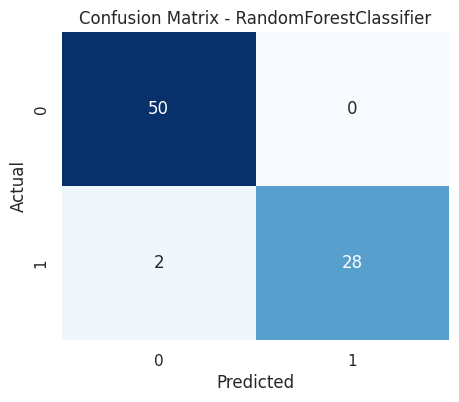

In [16]:
# ==========================================================
# Section 14: Random Forest
# ==========================================================

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

rf.fit(X_train, y_train)

rf_results = evaluate_model(
    rf,
    X_test,
    y_test
)

results.append(rf_results)

GaussianNB
Accuracy : 0.9750
Precision: 0.9375
Recall   : 1.0000
F1-Score : 0.9677
ROC-AUC  : 1.0000

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        50
           1       0.94      1.00      0.97        30

    accuracy                           0.97        80
   macro avg       0.97      0.98      0.97        80
weighted avg       0.98      0.97      0.98        80



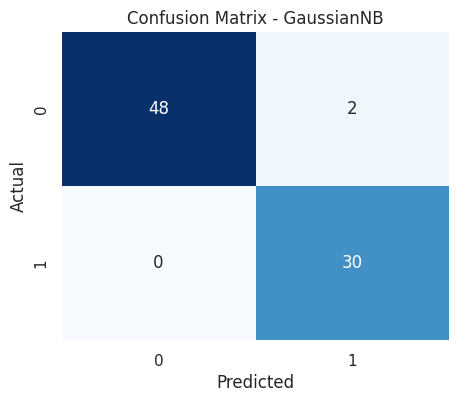

In [17]:

# ==========================================================
# Section 16: Gaussian Naive Bayes
# ==========================================================

from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

gnb.fit(X_train, y_train)

gnb_results = evaluate_model(
    gnb,
    X_test,
    y_test
)

results.append(gnb_results)

ExtraTreesClassifier
Accuracy : 0.9875
Precision: 1.0000
Recall   : 0.9667
F1-Score : 0.9831
ROC-AUC  : 1.0000

Classification Report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80



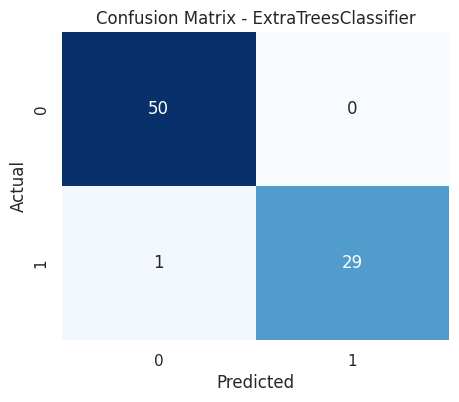

In [18]:
# ==========================================================
# Section 17: Extra Trees Classifier
# ==========================================================

from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

et.fit(X_train, y_train)

et_results = evaluate_model(
    et,
    X_test,
    y_test
)

results.append(et_results)

In [19]:
# =============================================================================
# Save Best Extra Trees Model
# =============================================================================

import joblib
import os

os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(
    et,
    os.path.join(MODEL_DIR, "extra_trees.pkl")
)

print("Extra Trees model saved successfully.")

Extra Trees model saved successfully.


In [20]:
print(MODEL_DIR)

/content/drive/MyDrive/CKD Research Project/Saved_Models


XGBClassifier
Accuracy : 0.9625
Precision: 1.0000
Recall   : 0.9000
F1-Score : 0.9474
ROC-AUC  : 0.9993

Classification Report
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        50
           1       1.00      0.90      0.95        30

    accuracy                           0.96        80
   macro avg       0.97      0.95      0.96        80
weighted avg       0.96      0.96      0.96        80



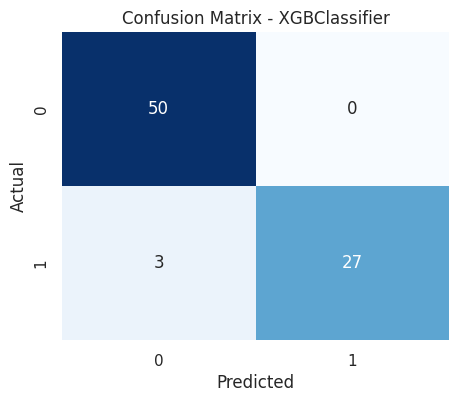

In [21]:
# ==========================================================
# Section 18: XGBoost
# ==========================================================

from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)

xgb_results = evaluate_model(
    xgb,
    X_test,
    y_test
)

results.append(xgb_results)

In [22]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00


CatBoostClassifier
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9993

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



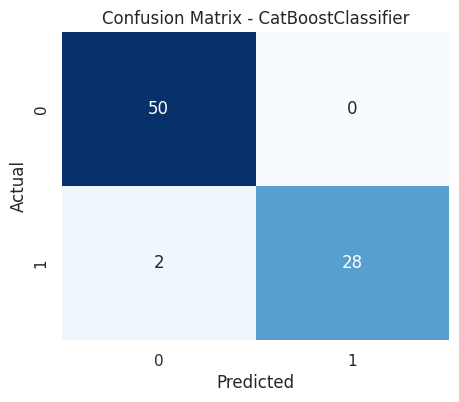

In [23]:
# ==========================================================
# Section 20: CatBoost
# ==========================================================

from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    random_state=RANDOM_STATE,
    verbose=False
)

cat.fit(X_train, y_train)

cat_results = evaluate_model(
    cat,
    X_test,
    y_test
)

results.append(cat_results)

[LightGBM] [Info] Number of positive: 119, number of negative: 200
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001048 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 524
[LightGBM] [Info] Number of data points in the train set: 319, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.373041 -> initscore=-0.519194
[LightGBM] [Info] Start training from score -0.519194
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

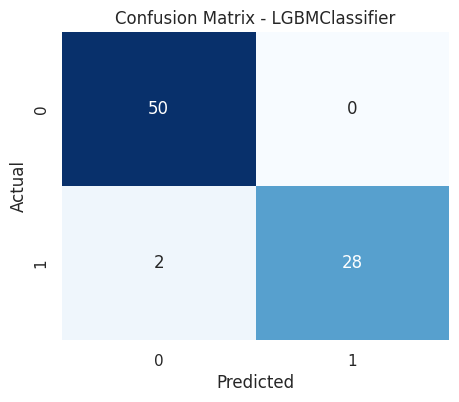

In [24]:
# ==========================================================
# Section 19: LightGBM
# ==========================================================

from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    random_state=RANDOM_STATE
)

lgbm.fit(X_train, y_train)

lgbm_results = evaluate_model(
    lgbm,
    X_test,
    y_test
)

results.append(lgbm_results)

In [25]:
# ==========================================================
# Section 21: Model Performance Comparison
# ==========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df.index = results_df.index + 1

results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,LogisticRegression,0.9875,0.967742,1.000000,0.983607,0.999333
2,KNeighborsClassifier,0.9875,0.967742,1.000000,0.983607,0.989000
3,ExtraTreesClassifier,0.9875,1.000000,0.966667,0.983051,1.000000
4,RandomForestClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
5,DecisionTreeClassifier,0.9750,1.000000,0.933333,0.965517,0.966667
6,GaussianNB,0.9750,0.937500,1.000000,0.967742,1.000000
7,CatBoostClassifier,0.9750,1.000000,0.933333,0.965517,0.999333
8,LGBMClassifier,0.9750,1.000000,0.933333,0.965517,1.000000
9,XGBClassifier,0.9625,1.000000,0.900000,0.947368,0.999333


In [26]:
results_df = results_df.round(4)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,LogisticRegression,0.9875,0.9677,1.0000,0.9836,0.9993
2,KNeighborsClassifier,0.9875,0.9677,1.0000,0.9836,0.9890
3,ExtraTreesClassifier,0.9875,1.0000,0.9667,0.9831,1.0000
4,RandomForestClassifier,0.9750,1.0000,0.9333,0.9655,0.9993
5,DecisionTreeClassifier,0.9750,1.0000,0.9333,0.9655,0.9667
6,GaussianNB,0.9750,0.9375,1.0000,0.9677,1.0000
7,CatBoostClassifier,0.9750,1.0000,0.9333,0.9655,0.9993
8,LGBMClassifier,0.9750,1.0000,0.9333,0.9655,1.0000
9,XGBClassifier,0.9625,1.0000,0.9000,0.9474,0.9993


In [27]:
results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

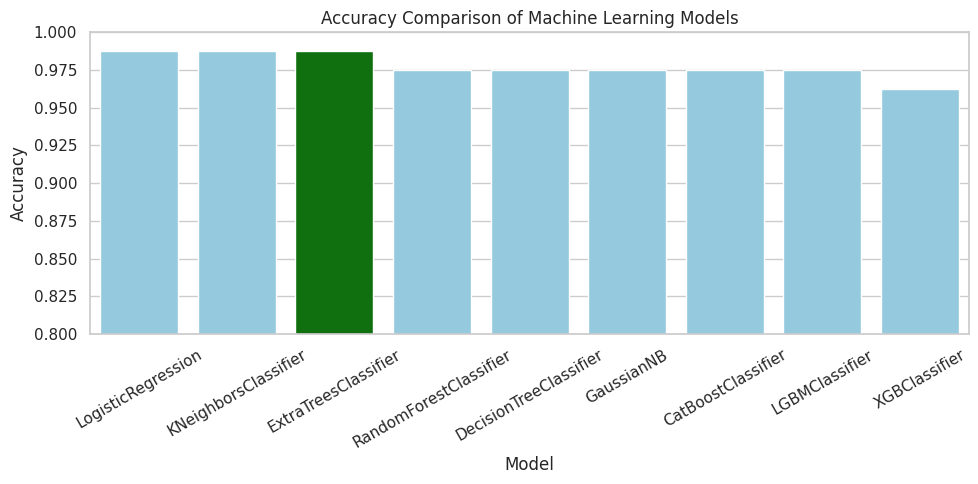

In [31]:
plt.figure(figsize=(10,5))

colors = ['green' if model == 'ExtraTreesClassifier' else 'skyblue'
          for model in results_df['Model']]

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    palette=colors
)

plt.xticks(rotation=30)
plt.ylim(0.80,1.00)

plt.title("Accuracy Comparison of Machine Learning Models")

plt.tight_layout()
plt.show()

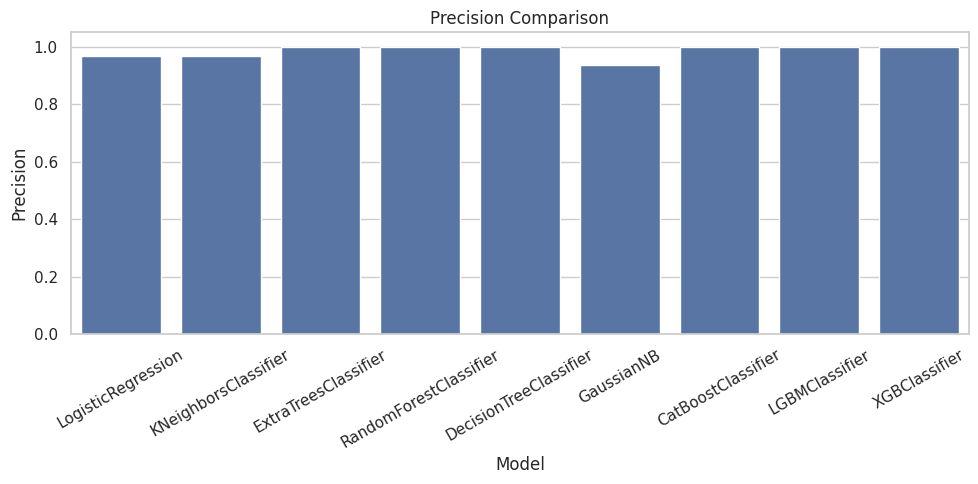

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Precision"
)

plt.xticks(rotation=30)

plt.title("Precision Comparison")

plt.tight_layout()

plt.show()

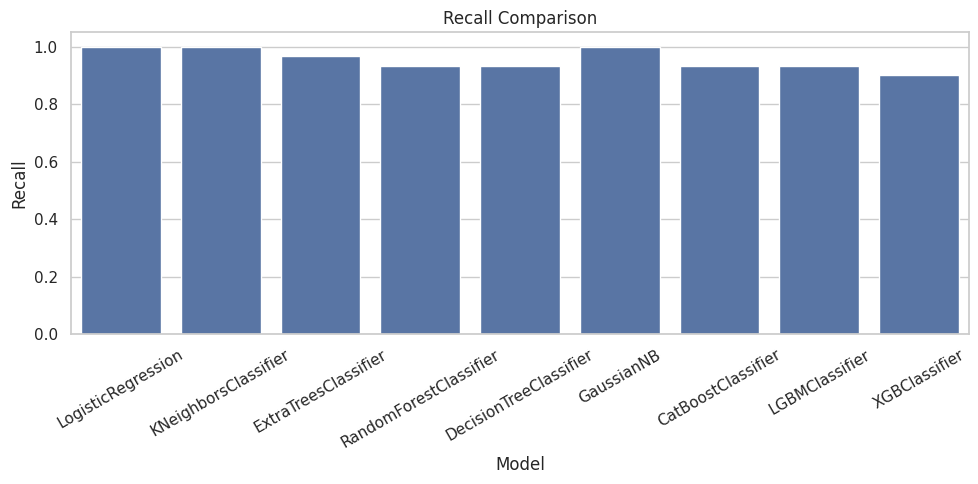

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Recall"
)

plt.xticks(rotation=30)

plt.title("Recall Comparison")

plt.tight_layout()

plt.show()

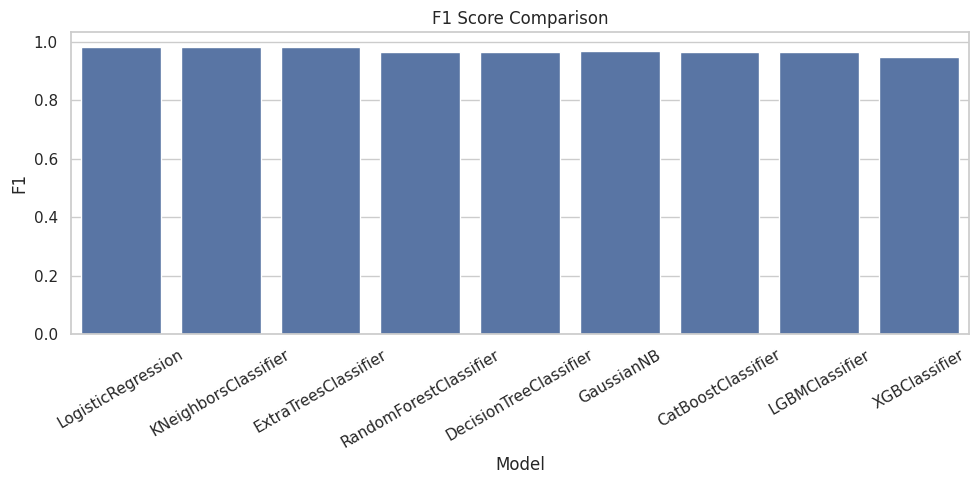

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1"
)

plt.xticks(rotation=30)

plt.title("F1 Score Comparison")

plt.tight_layout()

plt.show()

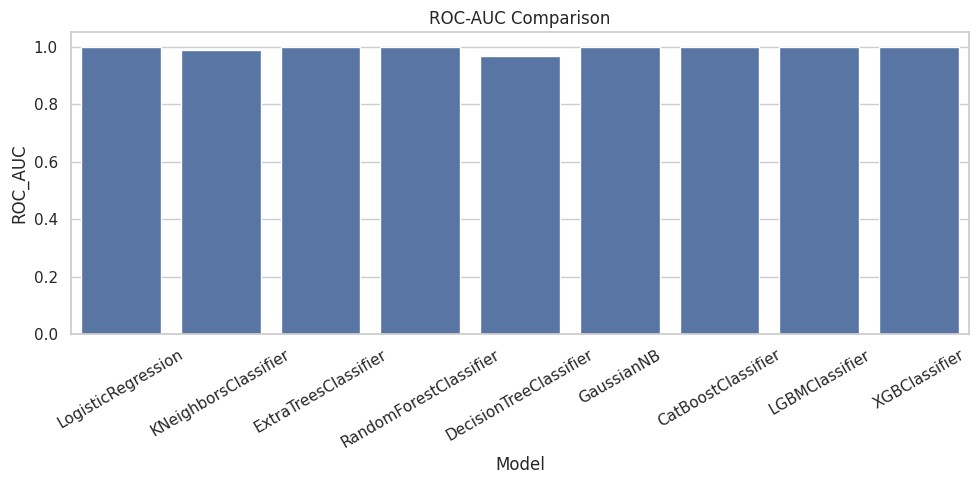

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC_AUC"
)

plt.xticks(rotation=30)

plt.title("ROC-AUC Comparison")

plt.tight_layout()

plt.show()

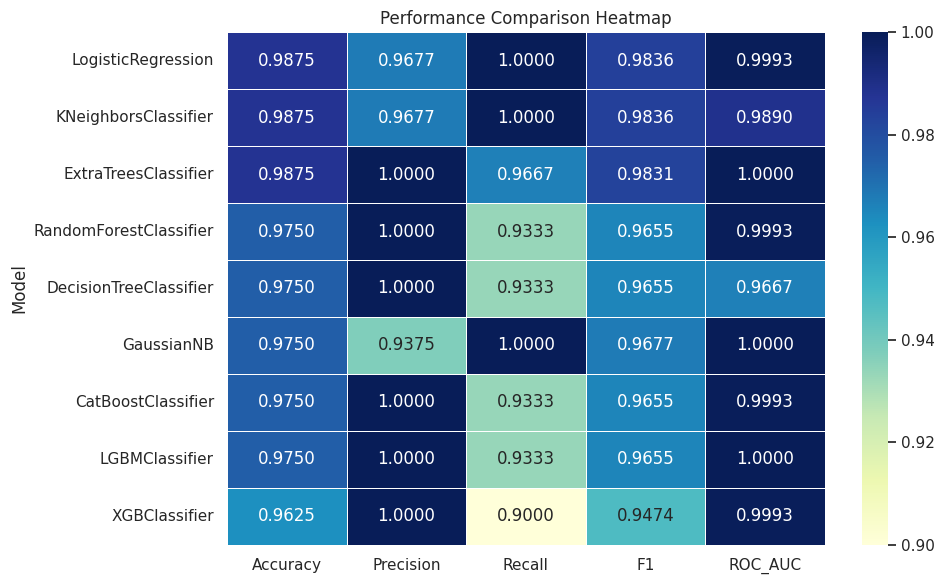

In [ ]:
# ==========================================================
# Section 23: Performance Heatmap
# ==========================================================

plt.figure(figsize=(10,6))

heatmap_data = results_df.set_index("Model")

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="YlGnBu",
    fmt=".4f",
    linewidths=.5
)

plt.title("Performance Comparison Heatmap")

plt.tight_layout()

plt.show()

In [ ]:
plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "performance_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
# ==========================================================
# Section 24: 10-Fold Cross Validation
# ==========================================================

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=RANDOM_STATE))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    ),

    "LightGBM": LGBMClassifier(
        random_state=RANDOM_STATE,
        verbose=-1
    ),

    "CatBoost": CatBoostClassifier(
        random_state=RANDOM_STATE,
        verbose=0
    ),

    "Extra Trees": ExtraTreesClassifier(
        random_state=RANDOM_STATE
    )
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        estimator=model,
        X=X,
        y=y,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std": scores.std()
    })

cv_df = (
    pd.DataFrame(cv_results)
      .sort_values(by="Mean Accuracy", ascending=False)
      .reset_index(drop=True)
)

cv_df.index += 1

print("=" * 60)
print("10-Fold Cross Validation Results")
print("=" * 60)

display(cv_df.round(4))

# Save Results
cv_df.round(4).to_csv(
    RESULT_DIR + "/cross_validation_results.csv",
    index=False
)

10-Fold Cross Validation Results


,Model,Mean Accuracy,Std
1,Extra Trees,0.9975,0.0075
2,Logistic Regression,0.9950,0.0100
3,LightGBM,0.9950,0.0100
4,Random Forest,0.9900,0.0166
5,XGBoost,0.9875,0.0125
6,CatBoost,0.9875,0.0125
7,Decision Tree,0.9775,0.0208
8,KNN,0.9699,0.0312
9,Gaussian Naive Bayes,0.9650,0.0450


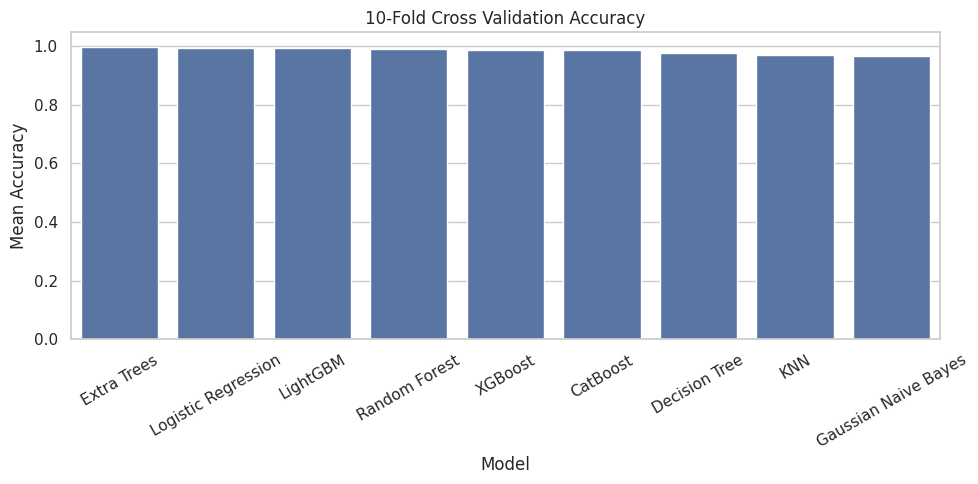

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean Accuracy"
)

plt.xticks(rotation=30)

plt.title("10-Fold Cross Validation Accuracy")

plt.tight_layout()

plt.show()

In [ ]:
plt.savefig(
    os.path.join(FIGURE_DIR, "10_fold.png"),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
for k in models.keys():
    print(k)

Random Forest
XGBoost
LightGBM
Extra Trees


In [ ]:
# ==========================================================
# Section 25 : Overfitting Analysis
# ==========================================================

overfit_results = []

trained_models = {
    "Logistic Regression": (log_reg, X_train_scaled, X_test_scaled),
    "KNN": (knn, X_train_scaled, X_test_scaled),
    "Decision Tree": (dt, X_train, X_test),
    "Random Forest": (rf, X_train, X_test),
    "Gaussian NB": (gnb, X_train, X_test),
    "XGBoost": (xgb, X_train, X_test),
    "LightGBM": (lgbm, X_train, X_test)
}

for name,(model,xtr,xte) in trained_models.items():

    train_acc = model.score(xtr,y_train)
    test_acc  = model.score(xte,y_test)

    gap = train_acc-test_acc

    if gap<0.02:
        status="Excellent"

    elif gap<0.05:
        status="Acceptable"

    else:
        status="Possible Overfitting"

    overfit_results.append([
        name,
        train_acc,
        test_acc,
        gap,
        status
    ])

overfit_df=pd.DataFrame(
    overfit_results,
    columns=[
        "Model",
        "Train Accuracy",
        "Test Accuracy",
        "Gap",
        "Assessment"
    ]
)

overfit_df.round(4)

,Model,Train Accuracy,Test Accuracy,Gap,Assessment
0,Logistic Regression,1.0000,0.9875,0.0125,Excellent
1,KNN,0.9812,0.9875,-0.0063,Excellent
2,Decision Tree,1.0000,0.9750,0.0250,Acceptable
3,Random Forest,1.0000,0.9750,0.0250,Acceptable
4,Gaussian NB,0.9624,0.9750,-0.0126,Excellent
5,XGBoost,1.0000,0.9625,0.0375,Acceptable
6,LightGBM,1.0000,0.9750,0.0250,Acceptable


In [ ]:
# ============================================================
# Section 26 : Hyperparameter Tuning - Random Forest
# ============================================================

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Parameter Grid
rf_param_grid = {

    "n_estimators": [100, 200],

    "max_depth": [None, 5, 10],

    "min_samples_split": [2, 5],

    "min_samples_leaf": [1, 2]

}

# Grid Search
rf_grid = GridSearchCV(

    estimator=RandomForestClassifier(

        random_state=RANDOM_STATE

    ),

    param_grid=rf_param_grid,

    cv=5,

    scoring="roc_auc",

    n_jobs=-1,

    verbose=1

)

# Train
rf_grid.fit(X_train, y_train)

# Best Model
best_rf = rf_grid.best_estimator_

print("=" * 60)
print("Best Parameters")
print("=" * 60)
print(rf_grid.best_params_)

print("\nBest Cross Validation ROC-AUC")
print(rf_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross Validation ROC-AUC
0.999375


RandomForestClassifier
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9993

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



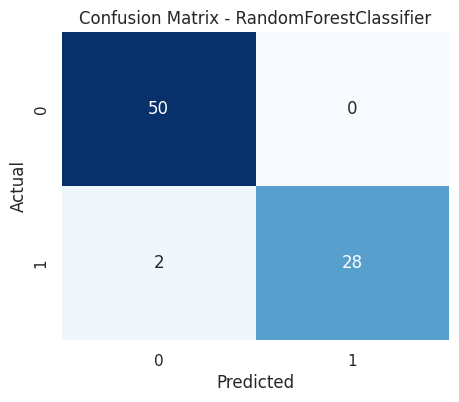

In [ ]:
rf_tuned_results = evaluate_model(
    best_rf,
    X_test,
    y_test
)

rf_tuned_results["Model"] = "Tuned Random Forest"

In [ ]:
# ============================================================
# XGBoost Hyperparameter Tuning
# ============================================================

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Parameter Grid
xgb_param_grid = {

    "n_estimators": [100, 200],

    "max_depth": [3, 5, 7],

    "learning_rate": [0.01, 0.1],

    "subsample": [0.8, 1.0],

    "colsample_bytree": [0.8, 1.0]
}

# Grid Search
xgb_grid = GridSearchCV(

    estimator=XGBClassifier(

        random_state=RANDOM_STATE,
        eval_metric="logloss"

    ),

    param_grid=xgb_param_grid,

    cv=5,

    scoring="roc_auc",

    n_jobs=-1,

    verbose=1

)

# Train
xgb_grid.fit(X_train, y_train)

# Best Model
best_xgb = xgb_grid.best_estimator_

print("="*60)
print("Best Parameters")
print("="*60)
print(xgb_grid.best_params_)

print("\nBest Cross Validation ROC-AUC")
print(xgb_grid.best_score_)

# ============================================================
# Test Set Evaluation
# ============================================================

y_pred = best_xgb.predict(X_test)
y_prob = best_xgb.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n" + "="*60)
print("Test Performance")
print("="*60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

Best Cross Validation ROC-AUC
0.9991576086956522

Test Performance
Accuracy : 0.9625
Precision: 1.0000
Recall   : 0.9000
F1 Score : 0.9474
ROC-AUC  : 0.9987

Classification Report
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        50
           1       1.00      0.90      0.95        30

    accuracy                           0.96        80
   macro avg       0.97      0.95      0.96        80
weighted avg       0.96      0.96      0.96        80


Confusion Matrix
[[50  0]
 [ 3 27]]


XGBClassifier
Accuracy : 0.9625
Precision: 1.0000
Recall   : 0.9000
F1-Score : 0.9474
ROC-AUC  : 0.9987

Classification Report
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        50
           1       1.00      0.90      0.95        30

    accuracy                           0.96        80
   macro avg       0.97      0.95      0.96        80
weighted avg       0.96      0.96      0.96        80



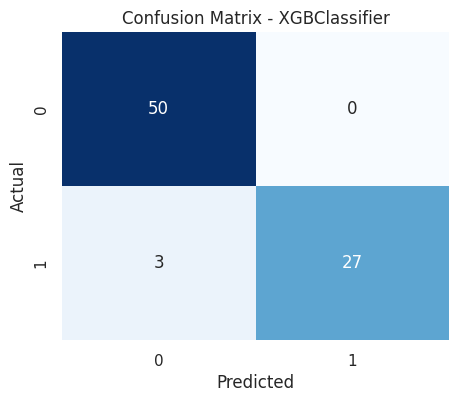

In [ ]:
xgb_tuned_results = evaluate_model(
    best_xgb,
    X_test,
    y_test
)
xgb_tuned_results["Model"] = "Tuned XGBoost"

In [ ]:
# ============================================================
# LightGBM Hyperparameter Tuning
# ============================================================

from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

# Parameter Grid
lgb_param_grid = {

    "n_estimators": [100, 200],

    "learning_rate": [0.01, 0.1],

    "num_leaves": [31, 50],

    "max_depth": [-1, 5, 10],

    "subsample": [0.8, 1.0],

    "colsample_bytree": [0.8, 1.0]

}

# Grid Search
lgb_grid = GridSearchCV(

    estimator=LGBMClassifier(

        random_state=RANDOM_STATE,
        verbose=-1

    ),

    param_grid=lgb_param_grid,

    cv=5,

    scoring="roc_auc",

    n_jobs=-1,

    verbose=1

)

# Train
lgb_grid.fit(X_train, y_train)

# Best Model
best_lgb = lgb_grid.best_estimator_

print("=" * 60)
print("Best Parameters")
print("=" * 60)
print(lgb_grid.best_params_)

print("\nBest Cross Validation ROC-AUC")
print(lgb_grid.best_score_)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Parameters
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 31, 'subsample': 0.8}

Best Cross Validation ROC-AUC
0.9995833333333334


LGBMClassifier
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 1.0000

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



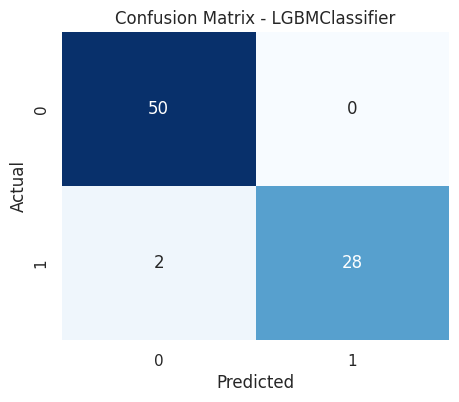

In [ ]:
lgb_tuned_results=evaluate_model(

    best_lgb,

    X_test,

    y_test

)
lgb_tuned_results["Model"] = "Tuned LightGBM"

In [ ]:
# ============================================================
# Section 26 : Hyperparameter Tuning - Extra Trees
# ============================================================

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import GridSearchCV

# Parameter Grid
et_param_grid = {

    "n_estimators": [100, 200],

    "max_depth": [None, 5, 10],

    "min_samples_split": [2, 5],

    "min_samples_leaf": [1, 2],

    "max_features": ["sqrt", "log2"]

}

# Grid Search
et_grid = GridSearchCV(

    estimator=ExtraTreesClassifier(

        random_state=RANDOM_STATE

    ),

    param_grid=et_param_grid,

    cv=5,

    scoring="roc_auc",

    n_jobs=-1,

    verbose=1

)

# Train
et_grid.fit(X_train, y_train)

# Best Model
best_et = et_grid.best_estimator_

print("=" * 60)
print("Best Parameters")
print("=" * 60)
print(et_grid.best_params_)

print("\nBest Cross Validation ROC-AUC")
print(et_grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross Validation ROC-AUC
1.0


ExtraTreesClassifier
Accuracy : 0.9875
Precision: 1.0000
Recall   : 0.9667
F1-Score : 0.9831
ROC-AUC  : 1.0000

Classification Report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80



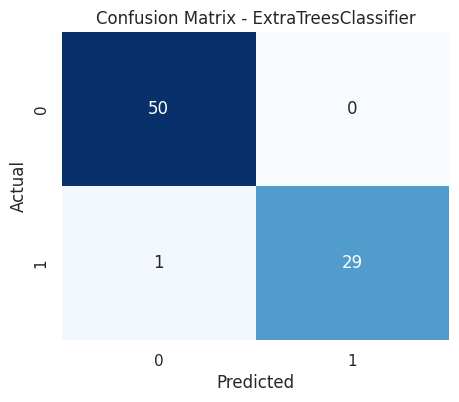

{'Model': 'Tuned Extra Trees',
 'Accuracy': 0.9875,
 'Precision': 1.0,
 'Recall': 0.9666666666666667,
 'F1': 0.9830508474576272,
 'ROC_AUC': np.float64(1.0)}

In [ ]:
et_tuned_results = evaluate_model(
    best_et,
    X_test,
    y_test
)

et_tuned_results["Model"] = "Tuned Extra Trees"

et_tuned_results

In [ ]:
tuned_results = pd.DataFrame([

    rf_tuned_results,

    xgb_tuned_results,

    lgb_tuned_results,

    et_tuned_results

])

tuned_results = tuned_results.round(4)

display(tuned_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Tuned Random Forest,0.9750,1.0,0.9333,0.9655,0.9993
1,Tuned XGBoost,0.9625,1.0,0.9000,0.9474,0.9987
2,Tuned LightGBM,0.9750,1.0,0.9333,0.9655,1.0000
3,Tuned Extra Trees,0.9875,1.0,0.9667,0.9831,1.0000


In [ ]:
# ==========================================================
# Section : Best Hyperparameter Summary
# ==========================================================

import pandas as pd
import os

best_params = [

    {
        "Model": "Random Forest",
        **rf_grid.best_params_
    },

    {
        "Model": "XGBoost",
        **xgb_grid.best_params_
    },

    {
        "Model": "LightGBM",
        **lgb_grid.best_params_
    },

    {
        "Model": "Extra Trees",
        **et_grid.best_params_
    }

]

best_params_df = pd.DataFrame(best_params)

display(best_params_df)

# Save Results
best_params_df.to_csv(
    os.path.join(RESULT_DIR, "best_hyperparameters.csv"),
    index=False
)

print("✅ Best hyperparameters saved successfully.")

,Model,max_depth,min_samples_leaf,min_samples_split,n_estimators,colsample_bytree,learning_rate,subsample,num_leaves,max_features
0,Random Forest,NaN,1.0,5.0,200,NaN,NaN,NaN,NaN,NaN
1,XGBoost,3.0,NaN,NaN,200,0.8,0.1,0.8,NaN,NaN
2,LightGBM,-1.0,NaN,NaN,100,0.8,0.1,0.8,31.0,NaN
3,Extra Trees,NaN,1.0,2.0,100,NaN,NaN,NaN,NaN,sqrt


✅ Best hyperparameters saved successfully.


In [ ]:
# ==========================================================
# Section 25: Statistical Significance Analysis
# Wilcoxon Signed-Rank Test
# ==========================================================

from scipy.stats import wilcoxon
import pandas as pd

print("=" * 80)
print("STATISTICAL SIGNIFICANCE ANALYSIS")
print("=" * 80)

# ----------------------------------------------------------
# Collect 10-Fold Cross Validation Scores
# ----------------------------------------------------------

cv_scores = {}

for name, model in models.items():

    scores = cross_val_score(
        estimator=model,
        X=X,
        y=y,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_scores[name] = scores

# ----------------------------------------------------------
# Display Available Models
# ----------------------------------------------------------

print("\nModels Available for Comparison:")
print(list(cv_scores.keys()))

# ----------------------------------------------------------
# Best Model
# ----------------------------------------------------------

best_model_name = "Extra Trees"

# Automatically compare with every other available model
comparison_models = [
    model
    for model in cv_scores.keys()
    if model != best_model_name
]

results = []

print("\n")
print("=" * 80)
print(f"Comparing {best_model_name} with Other Models")
print("=" * 80)

for model_name in comparison_models:

    stat, p_value = wilcoxon(
        cv_scores[best_model_name],
        cv_scores[model_name],
        alternative="two-sided"
    )

    significant = "Yes" if p_value < 0.05 else "No"

    print(f"\n{best_model_name} vs {model_name}")
    print(f"Statistic    : {stat:.4f}")
    print(f"P-value      : {p_value:.4f}")
    print(f"Significant? : {significant}")

    results.append({

        "Best Model": best_model_name,

        "Compared Model": model_name,

        "Statistic": round(stat,4),

        "P-value": round(p_value,4),

        "Significant": significant

    })

# ----------------------------------------------------------
# Create Result DataFrame
# ----------------------------------------------------------

wilcoxon_df = pd.DataFrame(results)

print("\n")
print("=" * 80)
print("Wilcoxon Signed-Rank Test Results")
print("=" * 80)

display(wilcoxon_df)

# ----------------------------------------------------------
# Save Results
# ----------------------------------------------------------

wilcoxon_df.to_csv(
    RESULT_DIR + "/wilcoxon_test_results.csv",
    index=False
)

print("\nResults saved successfully.")

STATISTICAL SIGNIFICANCE ANALYSIS

Models Available for Comparison:
['Random Forest', 'XGBoost', 'LightGBM', 'Extra Trees']


Comparing Extra Trees with Other Models

Extra Trees vs Random Forest
Statistic    : 2.0000
P-value      : 0.5000
Significant? : No

Extra Trees vs XGBoost
Statistic    : 3.5000
P-value      : 0.2188
Significant? : No

Extra Trees vs LightGBM
Statistic    : 2.0000
P-value      : 1.0000
Significant? : No


Wilcoxon Signed-Rank Test Results


,Best Model,Compared Model,Statistic,P-value,Significant
0,Extra Trees,Random Forest,2.0,0.5000,No
1,Extra Trees,XGBoost,3.5,0.2188,No
2,Extra Trees,LightGBM,2.0,1.0000,No



Results saved successfully.


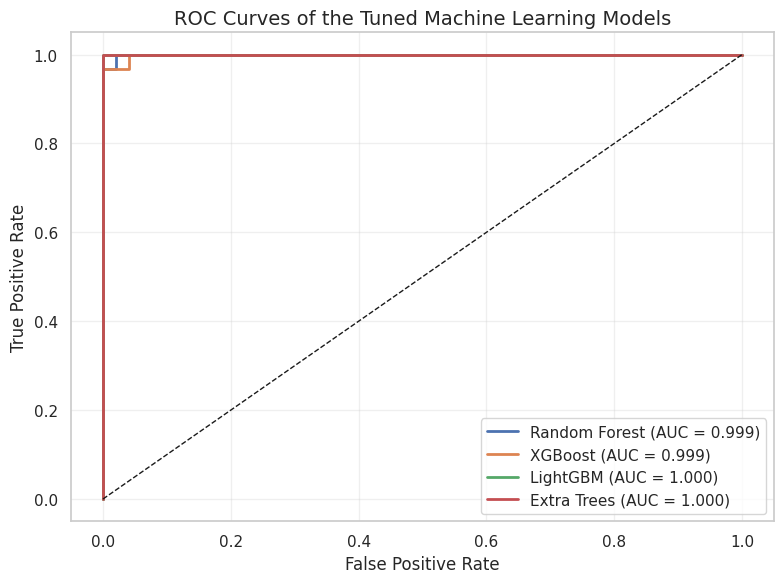

In [ ]:
# ==========================================================
# Section 27 : ROC Curve
# ==========================================================

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

models = {

    "Random Forest": best_rf,

    "XGBoost": best_xgb,

    "LightGBM": best_lgb,

    "Extra Trees": best_et

}

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], 'k--', lw=1)

plt.xlabel("False Positive Rate", fontsize=12)

plt.ylabel("True Positive Rate", fontsize=12)

plt.title("ROC Curves of the Tuned Machine Learning Models", fontsize=14)

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

# Save Figure
plt.savefig(
    os.path.join(FIGURE_DIR, "ROC_Curve_Tuned_Models.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "roc_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

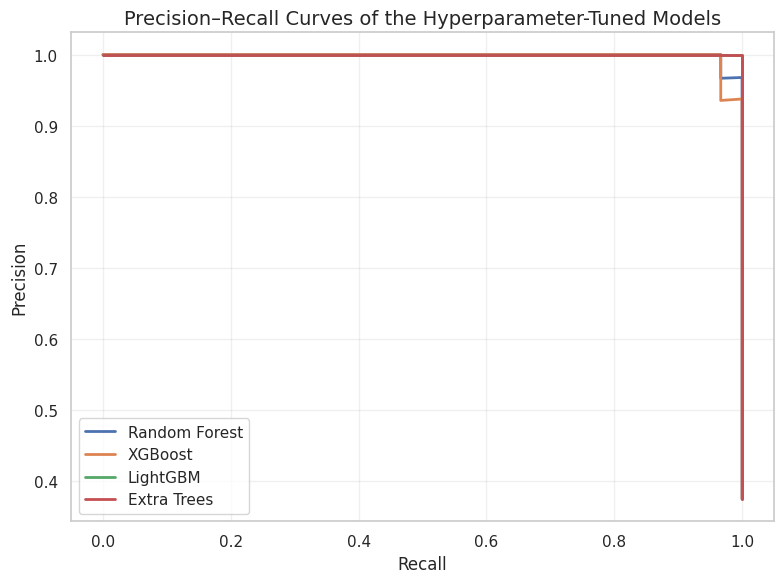

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

for name, model in models.items():

    prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        prob
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=name
    )

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title("Precision–Recall Curves of the Hyperparameter-Tuned Models", fontsize=14)

plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save Figure
plt.savefig(
    os.path.join(FIGURE_DIR, "PR_Curve_Tuned_Models.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "precision_recall_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
# ==========================================================
# Section 29 : Feature Importance
# ==========================================================

importances = best_et.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
2,sg,0.178550
19,dm,0.119199
18,htn,0.112364
14,hemo,0.104648
15,pcv,0.104163
3,al,0.086755
17,rbcc,0.046604
21,appet,0.038239
22,pe,0.032100
6,pc,0.026819


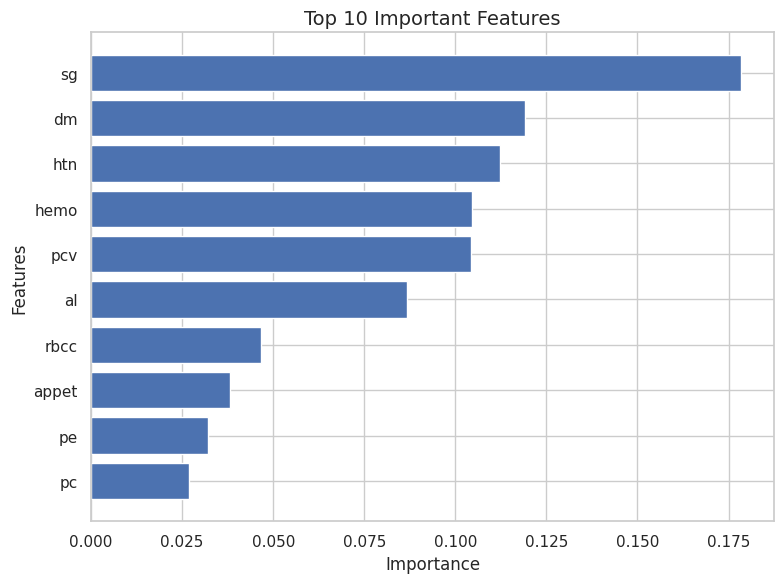

In [ ]:
top10 = feature_importance.head(10)

plt.figure(figsize=(8,6))

plt.barh(
    top10["Feature"][::-1],
    top10["Importance"][::-1]
)

plt.xlabel("Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.title("Top 10 Important Features", fontsize=14)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "Feature_Importance_ExtraTrees.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import joblib

joblib.dump(

    best_rf,

    "best_ckd_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


<Figure size 600x500 with 0 Axes>

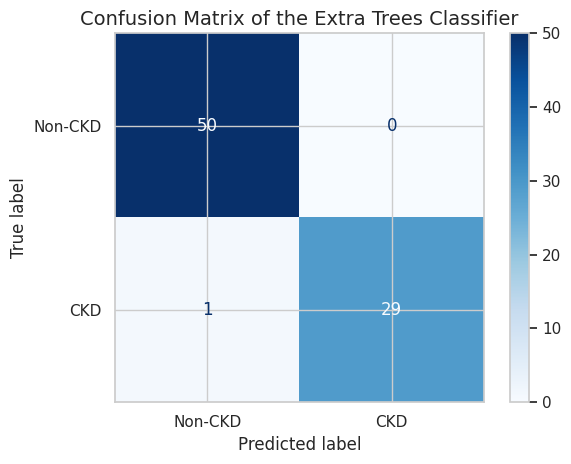

In [ ]:
# ==========================================================
# Section 29 : Confusion Matrix (Best Model - Extra Trees)
# ==========================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prediction
y_pred = best_et.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-CKD", "CKD"]
)

disp.plot(
    cmap="Blues",
    values_format='d'
)

plt.title("Confusion Matrix of the Extra Trees Classifier", fontsize=14)

plt.tight_layout()

# Save Figure
plt.savefig(
    os.path.join(FIGURE_DIR, "Confusion_Matrix_ExtraTrees.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# Section 30 : Save Best Machine Learning Model
# ==========================================================

import os
import joblib

# ----------------------------------------------------------
# Output Directories
# ----------------------------------------------------------

FIGURE_DIR = "/content/drive/MyDrive/CKD Research Project/Figures"
RESULT_DIR = "/content/drive/MyDrive/CKD Research Project/Results"
MODEL_DIR = "/content/drive/MyDrive/CKD Research Project/Saved_Models"

# Create folders if they do not exist
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# ----------------------------------------------------------
# Select Best Model
# ----------------------------------------------------------

# Replace this if another model performs better
best_model = best_rf
best_model_name = "RandomForest"

# ----------------------------------------------------------
# Save Model
# ----------------------------------------------------------

model_path = os.path.join(
    MODEL_DIR,
    f"{best_model_name}.pkl"
)

joblib.dump(best_model, model_path)

print("=" * 60)
print(" Best Machine Learning Model Saved Successfully")
print("=" * 60)
print(f"Model Name : {best_model_name}")
print(f"Location   : {model_path}")

 Best Machine Learning Model Saved Successfully
Model Name : RandomForest
Location   : /content/drive/MyDrive/CKD Research Project/Saved_Models/RandomForest.pkl
